# Predicting NFL QB Career Stats From a First Name

This notebook builds a **multi-output neural network** in PyTorch that reads a quarterback's first name
and tries to predict the following stats:

1. Career passing **touchdowns**
2. Career **interceptions**
3. Career passing **yards**
4. Career **passer rating**
5. Career **Super Bowl wins**

## Hypothesis: Is a first name actually predictive of NFL success?
Most likely, yes. There's no way "Cornelius," "Julian," or "Laken" are winning superbowls or throwing 4000 yard seasons.

But really, this is just a fun way to get some hands-on experience with deep-learning patterns.
I'll be using techniques such as embedding/vectorization, LSTMs, normalization and reverse scaling,
and other PyTorch shit.

## Step 1 — Install and import dependencies

Before we can do anything we need our tools. Here's the cast:

- **`nflreadpy`** — pulls real NFL data (play-by-play, player stats, rosters…) from the
  [nflverse](https://github.com/nflverse) project. This is where our QB stats come from.
- **`torch`** (PyTorch) for the deep-learning
- **`pandas`** / **`numpy`** — tabular data and math
- **`matplotlib`** — plotting
- **`scikit-learn`** — Normalization tool

In [1]:
# Dependencies are declared in pyproject.toml: `uv sync` installs them.

import matplotlib.pyplot as plt
import nflreadpy as nfl  # NFL data loader (returns Polars DataFrames)
import numpy as np
import pandas as pd
import polars as pl  # nflreadpy's native DataFrame type; we'll convert to pandas
from sklearn.preprocessing import MinMaxScaler
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

from dataglazer_nfl.config import EXTERNAL_DATA_DIR
from dataglazer_nfl.viz.style import apply_style

# --- Reproducibility -------------------------------------------------------
# Seeding torch (and numpy) means random weight init and data shuffling are
# identical on every run, so the loss curve and predictions are repeatable.
torch.manual_seed(42)
np.random.seed(42)

# We'll train on the CPU. It's plenty fast for a dataset this small (~250 rows),
# and keeping everything on CPU avoids subtle non-determinism on GPU/MPS.
device = torch.device("cpu")
print("PyTorch version:", torch.__version__)
print("Using device:", device)

PyTorch version: 2.13.0
Using device: cpu


## Step 2 — Pull QB career passing stats

Now we fetch the raw data. `nflreadpy.load_player_stats()` returns **per-season** stat lines for
every player. Limiting to `summary_level="reg"` (regular-season totals) across every season nflverse
has reliable data for **1999 onward** because thats what nflverse has data on, then:

1. **Filter to QBs only** (`position == "QB"`).
2. **Aggregate to career totals** group by player_id and sum totals
3. **Compute career passer rating.** stats don't come with this so we're gonna use the official NFL formula
4. **Filter out part-timers.** The spec asks for "10+ starts." The seasonal stats table doesn't carry
   a true *starts* column, so we use **career games played** as an honest, close proxy and keep only
   QBs with **≥ 10 games** (and at least one pass attempt, so the rating math is well-defined).

The result is one row per real, rotation-level quarterback with their five career numbers.


In [2]:
# Pull regular-season player stats for every season nflverse covers well (1999+).
# This downloads a few MB and may take ~10s the first time (it's cached afterward).
seasons = list(range(1999, 2025))
raw = nfl.load_player_stats(seasons=seasons, summary_level="reg")

# Keep only quarterbacks.
qb = raw.filter(pl.col("position") == "QB")

# Collapse every season a QB played into a single career row.
# We group by player_id (stable & unique) and sum the counting stats.
career = (
    qb.group_by("player_id")
    .agg(
        [
            pl.col("player_display_name").first().alias("full_name"),
            pl.col("games").sum().alias("games"),  # proxy for "starts"
            pl.col("completions").sum().alias("completions"),
            pl.col("attempts").sum().alias("attempts"),
            pl.col("passing_yards").sum().alias("passing_yards"),
            pl.col("passing_tds").sum().alias("passing_tds"),
            pl.col("passing_interceptions").sum().alias("interceptions"),
        ]
    )
    # Require a real workload: >=10 career games and at least one attempt.
    .filter((pl.col("games") >= 10) & (pl.col("attempts") > 0))
    .to_pandas()  # hand off to pandas for the rest of the notebook
)


def passer_rating(df):
    """Official NFL passer rating, computed from career totals.

    The rating is the average of four capped components (completion %, yards/attempt,
    TD rate, and INT rate), each clamped to [0, 2.375], scaled to a 0-158.3 range.
    """
    cmp_pct = np.clip(((df.completions / df.attempts) - 0.3) * 5, 0, 2.375)
    ypa = np.clip(((df.passing_yards / df.attempts) - 3) * 0.25, 0, 2.375)
    td_rate = np.clip((df.passing_tds / df.attempts) * 20, 0, 2.375)
    int_rate = np.clip(2.375 - (df.interceptions / df.attempts) * 25, 0, 2.375)
    return (cmp_pct + ypa + td_rate + int_rate) / 6 * 100


career["passer_rating"] = passer_rating(career).round(1)

print(f"{len(career)} qualifying QBs (>=10 career games).")
career.sort_values("passing_yards", ascending=False).head(8)

258 qualifying QBs (>=10 career games).


,player_id,full_name,games,completions,attempts,passing_yards,passing_tds,interceptions,passer_rating
175,00-0019596,Tom Brady,335,7754,12052,89216,649,212,97.2
58,00-0020531,Drew Brees,287,7149,10558,80428,571,243,98.7
14,00-0010346,Peyton Manning,250,5799,8804,68201,513,223,98.1
65,00-0022924,Ben Roethlisberger,249,5444,8447,64128,418,211,93.5
139,00-0022942,Philip Rivers,244,5277,8134,63434,421,209,95.2
6,00-0023459,Aaron Rodgers,248,5368,8244,62945,503,116,102.6
47,00-0026143,Matt Ryan,234,5551,8464,62792,381,183,93.6
5,00-0026498,Matthew Stafford,222,5181,8176,59871,377,188,91.2


## Step 3 — Load Super Bowl winners and join the win counts

Our fifth target is **Super Bowl wins**, and that's not in the stats table — it lives in a separate
CSV (`data/nfl/superbowl-qbs.csv`) listing each Super Bowl and its winning quarterback. A QB who won
multiple times (Brady, Montana…) appears on multiple rows, so:

1. We **count how many times each name appears** → that's their Super Bowl win total.
2. We **join** those counts onto our career table by matching the full name.
3. Crucially, we **fill missing values with 0** — the vast majority of QBs never won a Super Bowl, and
   a *missing* join result means *zero* wins, not "unknown."

⚠️ **Heads-up on a real-world data gotcha:** our stats only go back to 1999, but the Super Bowl list
goes back to the 1960s. So legends like Joe Montana and John Elway are in the CSV but *not* in our
stats table — their win counts simply won't find a home and are dropped. We'll only successfully
attach wins for the **modern-era** winners (Brady, Manning, Mahomes, …). That's fine for a teaching
model, but it's an honest limitation worth naming.

In [3]:
# Each row = one Super Bowl; "Winning QB" repeats for multi-time winners.
sb = pd.read_csv(EXTERNAL_DATA_DIR / "superbowl-qbs.csv")

# Count titles per quarterback name.
sb_wins = sb["Winning QB"].value_counts()
print("Most Super Bowl wins in the file:")
print(sb_wins.head(5), "\n")

# Map win counts onto our QBs by full name; anyone not found -> 0 wins.
career["sb_wins"] = career["full_name"].map(sb_wins).fillna(0).astype(int)

matched = (career["sb_wins"] > 0).sum()
print(f"Attached Super Bowl wins to {matched} QBs in our 1999+ dataset.")
career[career["sb_wins"] > 0].sort_values("sb_wins", ascending=False)[
    ["full_name", "passing_tds", "passer_rating", "sb_wins"]
].head(8)

Most Super Bowl wins in the file:
Winning QB
Tom Brady          7
Terry Bradshaw     4
Joe Montana        4
Patrick Mahomes    3
Troy Aikman        3
Name: count, dtype: int64 

Attached Super Bowl wins to 18 QBs in our 1999+ dataset.


,full_name,passing_tds,passer_rating,sb_wins
175,Tom Brady,649,97.2,7
76,Troy Aikman,24,75.0,3
49,Patrick Mahomes,245,102.1,3
65,Ben Roethlisberger,418,93.5,2
235,Eli Manning,366,84.1,2
14,Peyton Manning,513,98.1,2
228,Joe Flacco,257,84.4,1
222,Kurt Warner,206,94.0,1


## Step 4 — Extract the first name

The whole premise is that the model sees **only a first name**. Our data has full names like
`"Patrick Mahomes"`, so we split on whitespace and keep the first token.

A subtle modeling point: many quarterbacks share a first name (there are a lot of "Matt"s and
"Josh"es). We deliberately **keep every row** rather than averaging duplicates. That means the model
sees, say, "Josh" paired with several different stat lines and is forced to learn the *average
tendency* of a "Josh" — which is exactly the (very weak) signal this toy problem is about.

In [4]:
# Take everything before the first space as the first name.
career["first_name"] = career["full_name"].str.split().str[0]

# Peek at how often first names repeat -- this is the only "signal" the model gets.
print("Most common QB first names in our data:")
print(career["first_name"].value_counts().head(8))
career[["first_name", "full_name", "passing_tds", "sb_wins"]].head()

Most common QB first names in our data:
first_name
Matt    9
Josh    5
Ryan    5
Jake    4
Mike    4
Tim     4
Drew    4
Jeff    4
Name: count, dtype: int64


,first_name,full_name,passing_tds,sb_wins
0,J.P.,J.P. Losman,33,0
1,Brett,Brett Favre,295,1
2,Brock,Brock Osweiler,37,0
3,Joey,Joey Harrington,79,0
4,Cleo,Cleo Lemon,8,0


## Step 5 — Build a character vocabulary and encode names as integer sequences

Neural networks eat **numbers**, not letters. So we convert each first name into a fixed-length list
of integers, one integer per character. Two ideas to understand here:

**1. The vocabulary.** We scan every first name, lowercase it, and collect the set of unique
characters that appear. We assign each character an integer ID. We reserve **ID 0 as a special
"padding / unknown" slot** — so the *real* characters start at ID 1. This reservation is what lets
the model gracefully handle names (and letters) it never saw during training: anything unknown just
maps to 0.

**2. Padding to a fixed length.** Names have different lengths ("Jo" vs "Jermichael"), but a tensor
needs a rectangular shape. So we pick a **max length of 15**: longer names are truncated, shorter
names are **padded with 0s** on the right until they're all length 15. Now every name is a clean
length-15 integer vector the network can batch together.

In [5]:
MAX_LEN = 15  # every name becomes exactly this many integers (pad/truncate)

# Build the vocabulary from all unique characters across all first names.
all_chars = sorted(set("".join(career["first_name"]).lower()))
# IDs start at 1; index 0 is reserved for padding AND unknown characters.
char_to_idx = {ch: i + 1 for i, ch in enumerate(all_chars)}
vocab_size = len(char_to_idx) + 1  # +1 for the reserved 0 slot

print(f"Vocabulary ({len(all_chars)} chars): {all_chars}")
print(f"vocab_size (incl. padding slot 0): {vocab_size}")


def encode_name(name: str) -> list[int]:
    """Turn a name into a length-MAX_LEN list of character IDs.

    Unknown characters -> 0. Short names are right-padded with 0; long names truncated.
    """
    name = name.lower()
    ids = [char_to_idx.get(ch, 0) for ch in name[:MAX_LEN]]  # unknown -> 0
    ids += [0] * (MAX_LEN - len(ids))  # pad to MAX_LEN
    return ids


# Encode every QB's first name into the integer matrix the model will train on.
X = np.array([encode_name(n) for n in career["first_name"]], dtype=np.int64)
print("Encoded matrix shape:", X.shape, "(rows = QBs, cols = char slots)")
print("Example ->", career["first_name"].iloc[0], "=>", X[0])

Vocabulary (27 chars): ['.', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
vocab_size (incl. padding slot 0): 28
Encoded matrix shape: (258, 15) (rows = QBs, cols = char slots)
Example -> J.P. => [11  1 17  1  0  0  0  0  0  0  0  0  0  0  0]


## Step 6 — Normalize the five targets to a 0–1 range

Our five targets live on wildly different scales: passing **yards** runs into the *tens of thousands*,
while **Super Bowl wins** is a single digit. If we fed those raw numbers to the network, the loss
would be utterly dominated by the yards term and the model would basically ignore the other four
targets.

The fix is **normalization**: we use scikit-learn's `MinMaxScaler` to linearly rescale each target
column so its minimum becomes 0 and its maximum becomes 1. Now all five targets are on equal footing
and contribute comparably to the loss.

**Why keep the scaler object?** The model will learn to predict these 0–1 values. To turn a prediction
back into a human-readable "37 touchdowns," we need to **reverse** the scaling — and the scaler
remembers the original min/max needed to do that. So we store it for inference time.

In [6]:
# The five targets, in a fixed column order we'll reuse everywhere.
TARGET_COLS = ["passing_tds", "interceptions", "passing_yards", "passer_rating", "sb_wins"]

# Fit a scaler that maps each column independently into [0, 1].
scaler = MinMaxScaler()
y = scaler.fit_transform(career[TARGET_COLS].values.astype(np.float32))

print("Targets normalized to [0, 1]. Column order:", TARGET_COLS)
print("Original ranges (min -> max):")
for col, lo, hi in zip(TARGET_COLS, scaler.data_min_, scaler.data_max_):
    print(f"  {col:15s}: {lo:8.1f} -> {hi:8.1f}")
print("\nExample normalized target row:", np.round(y[0], 3))

Targets normalized to [0, 1]. Column order: ['passing_tds', 'interceptions', 'passing_yards', 'passer_rating', 'sb_wins']
Original ranges (min -> max):
  passing_tds    :      0.0 ->    649.0
  interceptions  :      0.0 ->    244.0
  passing_yards  :      0.0 ->  89216.0
  passer_rating  :     29.3 ->    104.9
  sb_wins        :      0.0 ->      7.0

Example normalized target row: [0.051 0.139 0.07  0.612 0.   ]


## Step 7 — Wrap the data in a PyTorch `Dataset` and `DataLoader`

PyTorch likes data delivered through two small abstractions:

- A **`Dataset`** knows *how to fetch one example* — given an index `i`, return the encoded name
  (as a `long`/integer tensor, because the embedding layer indexes into a table) and its five
  normalized targets (as a `float` tensor).
- A **`DataLoader`** wraps the dataset and handles the boring-but-important logistics: grouping
  examples into **batches**, **shuffling** them each epoch (so the model doesn't memorize order), and
  feeding them to the training loop.

With ~250 QBs this is overkill convenience-wise, but it's the exact, idiomatic pattern you'd use on a
million-row dataset — so it's worth doing properly.

In [7]:
class QBNameDataset(Dataset):
    def __init__(self, X, y):
        # Names are integer indices -> long tensor. Targets are continuous -> float tensor.
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


dataset = QBNameDataset(X, y)
# Shuffle each epoch; batch_size 32 is a reasonable default for a small dataset.
loader = DataLoader(dataset, batch_size=32, shuffle=True)

# Sanity check: pull one batch and confirm the shapes.
xb, yb = next(iter(loader))
print("One batch -> names:", tuple(xb.shape), " targets:", tuple(yb.shape))

One batch -> names: (32, 15)  targets: (32, 5)


## Step 8 — Define the model: Embedding → LSTM → shared body → five heads

Here's the architecture, layer by layer, and the reasoning behind each piece:

- **Embedding layer.** Character IDs like `7` are arbitrary labels — `7` isn't "more" than `3`. The
  embedding layer turns each ID into a small *learned vector* (here, 16 numbers) that the network can
  shape during training to capture whatever about a character is useful. We pass `padding_idx=0` so the
  reserved padding/unknown slot stays a fixed zero vector and contributes nothing.

- **LSTM.** A name is a *sequence* of characters, and order matters ("Sam" ≠ "Mas"). An LSTM
  (Long Short-Term Memory) is a recurrent layer that reads the characters one at a time, maintaining a
  running "memory" of what it's seen. We use its **final hidden state** as a single fixed-size summary
  vector of the whole name.

- **Shared body** (`Linear → ReLU → Dropout`). A couple of fully-connected layers that further process
  that summary. **ReLU** adds non-linearity (so the model can learn curved relationships); **Dropout**
  randomly zeroes some activations during training, which combats overfitting on our tiny dataset.

- **Five output heads.** This is the **multi-task** part. Instead of one output, we attach five tiny
  independent `Linear` layers — one per target — that all branch off the *same* shared body. The shared
  body learns general "name features," and each head specializes those features into its own prediction.
  This is more efficient and often generalizes better than training five separate models.

In [8]:
class QBNameNet(nn.Module):
    def __init__(self, vocab_size, embed_dim=16, hidden_dim=64, body_dim=32, n_targets=5):
        super().__init__()
        # Map each character ID -> a learned embed_dim vector; padding stays zero.
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        # Read the character sequence; we'll use the final hidden state as a summary.
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        # Shared body: condense the LSTM summary into general-purpose name features.
        self.body = nn.Sequential(
            nn.Linear(hidden_dim, body_dim),
            nn.ReLU(),
            nn.Dropout(0.2),
        )
        # One small head per target. ModuleList registers them all as parameters.
        self.heads = nn.ModuleList([nn.Linear(body_dim, 1) for _ in range(n_targets)])

    def forward(self, x):
        emb = self.embedding(x)  # (batch, MAX_LEN, embed_dim)
        _, (h_n, _) = self.lstm(emb)  # h_n: (1, batch, hidden_dim)
        summary = h_n[-1]  # (batch, hidden_dim) -- last layer's hidden state
        features = self.body(summary)  # (batch, body_dim)
        # Run each head and stack into (batch, 5).
        outs = [head(features) for head in self.heads]
        return torch.cat(outs, dim=1)  # (batch, n_targets)


model = QBNameNet(vocab_size).to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"\nTrainable parameters: {n_params:,}")

QBNameNet(
  (embedding): Embedding(28, 16, padding_idx=0)
  (lstm): LSTM(16, 64, batch_first=True)
  (body): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (heads): ModuleList(
    (0-4): 5 x Linear(in_features=32, out_features=1, bias=True)
  )
)

Trainable parameters: 23,685


## Step 9 — Define the training loop

Training is the loop where the model actually *learns*. Each pass over the full dataset is an
**epoch**, and within each epoch we process the data batch by batch. For every batch we do the classic
four-step dance:

1. **Forward pass** — run the names through the model to get predictions.
2. **Compute the loss** — how wrong are we? We use **MSE (mean squared error)** between predicted and
   true normalized targets. Per the spec, we compute the MSE **for each of the five heads separately
   and sum them**, so every target pulls on the weights with equal force.
3. **Backward pass** — `loss.backward()` computes the gradient (the direction to nudge every weight to
   reduce the loss).
4. **Optimizer step** — **Adam** updates the weights using those gradients. We must `zero_grad()` first,
   because PyTorch *accumulates* gradients by default.

We train for **200 epochs** and print the average loss every 20 so we can watch it fall.

In [9]:
def train(model, loader, epochs=200, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    mse = nn.MSELoss()
    history = []  # average loss per epoch, for the plot in Step 10
    model.train()  # enable dropout

    for epoch in range(1, epochs + 1):
        epoch_loss = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()  # 1. clear old gradients
            preds = model(xb)  # 2. forward pass -> (batch, 5)

            # 3. MSE per head, summed across the five targets.
            loss = sum(mse(preds[:, i], yb[:, i]) for i in range(yb.shape[1]))

            loss.backward()  # 4. backprop
            optimizer.step()  # 5. update weights
            epoch_loss += loss.item()

        avg = epoch_loss / len(loader)
        history.append(avg)
        if epoch % 20 == 0 or epoch == 1:
            print(f"Epoch {epoch:3d}/{epochs}  |  loss = {avg:.4f}")
    return history

## Step 10 — Train the model and plot the loss curve

Now we actually run it. Watch the printed loss: it should start relatively high and **steadily fall**
as the network finds whatever weak patterns exist linking name-characters to stats.

The **loss curve** is the single most useful diagnostic in deep learning. A healthy run shows the loss
dropping fast at first, then flattening into a plateau as the model converges. If it were jagged or
rising, we'd suspect a learning rate that's too high or a bug. (Because the signal here is genuinely
weak, expect it to plateau at a non-trivial value — the model can only do so much with a first name.)

Epoch   1/200  |  loss = 0.6923


Epoch  20/200  |  loss = 0.1368


Epoch  40/200  |  loss = 0.1459


Epoch  60/200  |  loss = 0.1251


Epoch  80/200  |  loss = 0.1369


Epoch 100/200  |  loss = 0.1124


Epoch 120/200  |  loss = 0.1083


Epoch 140/200  |  loss = 0.0860


Epoch 160/200  |  loss = 0.0779


Epoch 180/200  |  loss = 0.1455


Epoch 200/200  |  loss = 0.0716


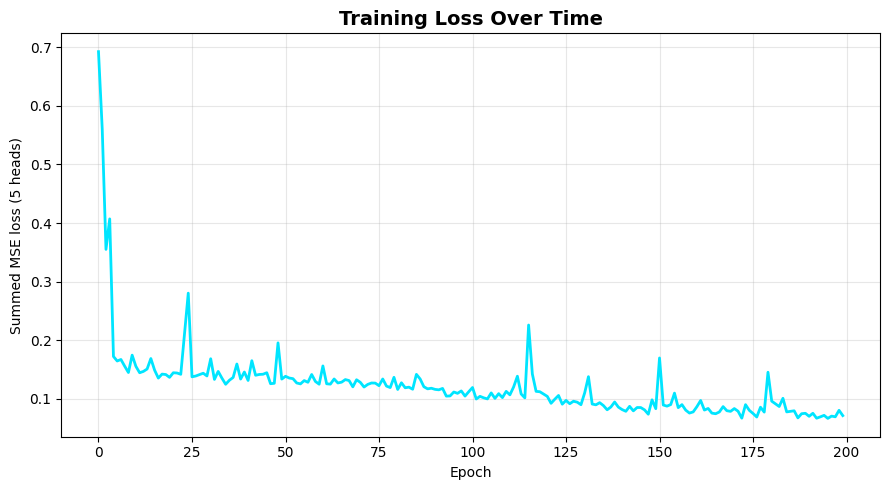

In [10]:
history = train(model, loader, epochs=200)

plt.figure(figsize=(9, 5))
plt.plot(history, color="#00E5FF", linewidth=2)
plt.title("Training Loss Over Time", fontsize=14, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Summed MSE loss (5 heads)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 11 — An inference function for any first name

Training is done; now we want to *use* the model. This helper takes any first-name string and returns
a clean dictionary of predicted career stats. The steps mirror training, but in reverse at the end:

1. **Encode** the name with the *same* `encode_name` function — so the vocabulary and padding match
   exactly what the model trained on. Unknown characters fall through to ID 0, which is why brand-new
   names don't crash anything.
2. **`model.eval()` + `torch.no_grad()`** — switch off dropout and skip gradient tracking, since we're
   only predicting, not learning. This makes inference deterministic and faster.
3. **Forward pass** to get five numbers in the normalized 0–1 space.
4. **Reverse the scaler** (`inverse_transform`) to convert those back into real-world units.
5. **Clean up** — round sensibly and clamp the counting stats (TDs, INTs, yards, SB wins) to be
   non-negative, since a model can technically output a small negative number that's nonsensical here.

In [11]:
def predict_stats(name: str) -> dict:
    """Predict career QB stats from a first name. Handles unseen names/characters gracefully."""
    model.eval()  # disable dropout
    encoded = torch.tensor([encode_name(name)], dtype=torch.long, device=device)
    with torch.no_grad():  # no gradients needed for inference
        norm_pred = model(encoded).cpu().numpy()  # shape (1, 5), still in [0,1] space

    # Reverse normalization back to real stat units.
    real = scaler.inverse_transform(norm_pred)[0]
    stats = dict(zip(TARGET_COLS, real))

    # Tidy up: counting stats can't be negative; round to readable precision.
    return {
        "Pass TDs": max(0, round(stats["passing_tds"])),
        "INTs": max(0, round(stats["interceptions"])),
        "Pass Yards": max(0, round(stats["passing_yards"])),
        "Passer Rating": round(stats["passer_rating"], 1),
        "SB Wins": max(0, round(stats["sb_wins"])),
    }


# Quick smoke test, including a name guaranteed not to be in the data.
print("Patrick ->", predict_stats("Patrick"))
print("Joe ->", predict_stats("Joe"))  # unseen chars handled gracefully

Patrick -> {'Pass TDs': 61, 'INTs': 44, 'Pass Yards': 9624, 'Passer Rating': np.float32(83.1), 'SB Wins': 0}
Joe -> {'Pass TDs': 115, 'INTs': 66, 'Pass Yards': 18247, 'Passer Rating': np.float32(81.1), 'SB Wins': 0}


## Step 12 — Predict for a fun mix of names

Let's point the model at a deliberately eclectic list: real NFL quarterbacks (whose names it saw),
common everyday names, and a few celebrities (whose names it almost certainly didn't). Seeing them
side by side is the fun payoff — and a reminder that the model is really just reacting to *letters*.

We collect the predictions into a pandas DataFrame so they print as a tidy, aligned table.

In [12]:
names = [
    # NFL QBs the model has seen:
    "Patrick",
    "Tom",
    "Aaron",
    "Josh",
    "Lamar",
    "Joe",
    # Everyday common names:
    "Michael",
    "David",
    "Chris",
    "Ashley",
    "Karen",
    # Celebrities / fun picks the model almost certainly never trained on:
    "Beyonce",
    "Elon",
    "Taylor",
    "Kanye",
    "Oprah",
    "Dwayne",
    "Keanu",
]

results = pd.DataFrame([{"First Name": n, **predict_stats(n)} for n in names])
results = results.sort_values("Pass TDs", ascending=False).reset_index(drop=True)
results

,First Name,Pass TDs,INTs,Pass Yards,Passer Rating,SB Wins
0,Tom,279,144,42232,88.500000,1
1,Aaron,248,132,37034,91.000000,1
2,Elon,136,80,20557,87.099998,0
3,Lamar,118,70,18374,83.599998,0
4,Joe,115,66,18247,81.099998,0
5,Josh,74,48,12032,80.300003,0
6,David,63,43,10380,80.699997,0
7,Patrick,61,44,9624,83.099998,0
8,Beyonce,59,39,9945,77.800003,0
9,Ashley,46,33,8192,76.599998,0


## Step 13 — Visualize predicted touchdowns

Finally, a chart. We plot each name's **predicted career touchdowns** as a horizontal bar, styled on a
dark background for that clean, modern look. Horizontal bars (sorted) make the name labels easy to read
and the ranking obvious at a glance — a nice way to *see* which names the model associates with gaudy
passing numbers.

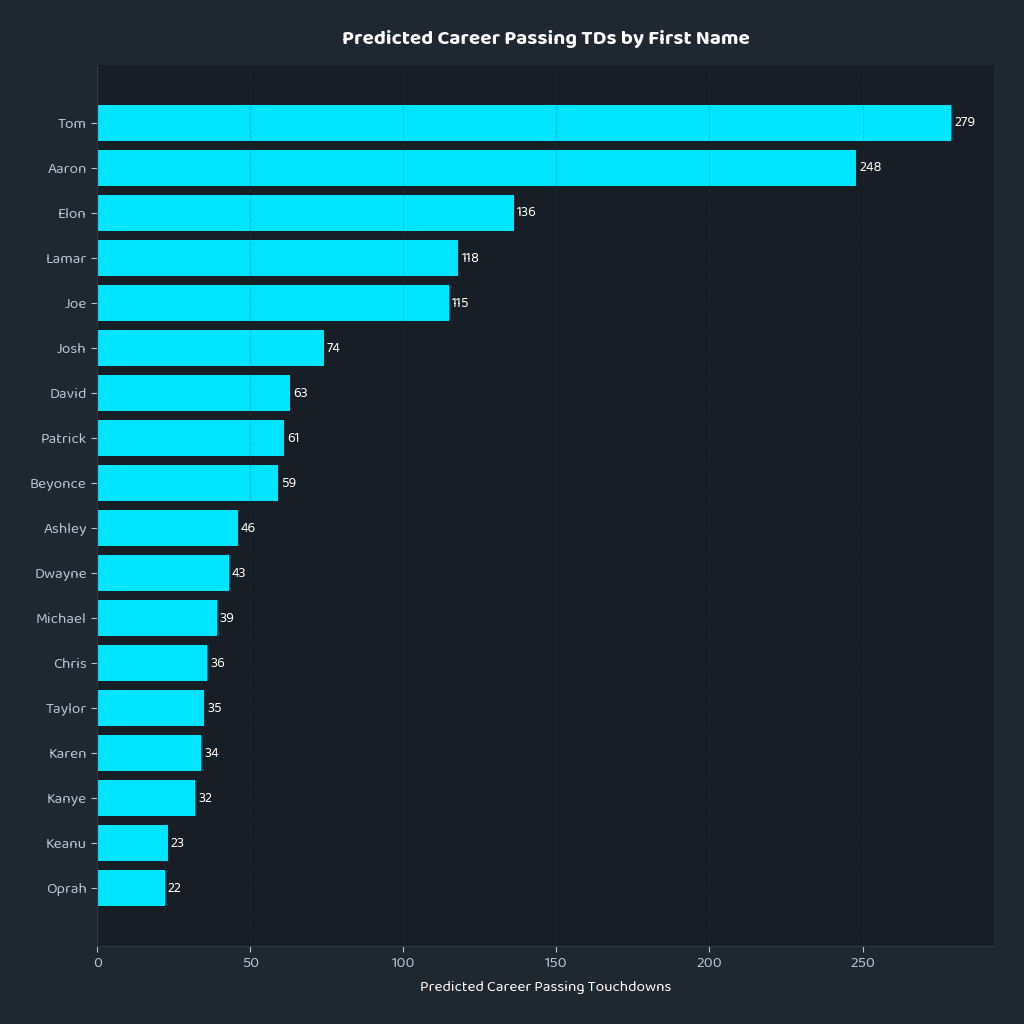

In [13]:
plot_df = results.sort_values("Pass TDs", ascending=True)  # ascending -> biggest on top in barh

apply_style()
fig, ax = plt.subplots(figsize=(10, 10))

bars = ax.barh(plot_df["First Name"], plot_df["Pass TDs"], color="#00E5FF", edgecolor="none")
# Annotate each bar with its value for readability.
for bar in bars:
    w = bar.get_width()
    ax.text(
        w + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{int(w)}",
        va="center",
        ha="left",
        color="white",
        fontsize=10,
    )

ax.set_title("Predicted Career Passing TDs by First Name", fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Predicted Career Passing Touchdowns", fontsize=11)
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## What the model learned — and its honest limitations

### What it actually learned
The network learned to map the **character patterns of a first name** to five career stats. With no
information beyond letters, the best it can do is pick up on the *average tendencies of names that
recur in the data* — e.g., because several productive QBs are named "Josh" or "Matt," the model nudges
those names toward higher numbers. It's essentially a smooth, learned lookup table over name-spelling,
with a little generalization to similar-looking unseen names.

### Limitations — read these before taking any prediction seriously 😄

1. **A first name has essentially no causal power over NFL success.** This is a *mechanics demo*, not a
   real predictor. Any apparent "skill" is the model memorizing which names happened to appear in the
   data. Performance on truly novel names is basically a stylistic guess.

2. **Tiny dataset.** ~250 QBs is minuscule for deep learning. The model can easily overfit, and the
   dropout/regularization only partly counters that. There's no train/validation/test split here — we
   trained on everything for simplicity, so we have **no honest measure of generalization.** A real
   project would hold out a test set.

3. **Data only goes back to 1999.** nflverse's player-stats coverage starts at 1999, so pre-1999
   legends (Montana, Elway, Marino, Bradshaw…) are missing entirely. This also means most historical
   **Super Bowl wins never got joined** — the SB-wins target is sparse and skewed toward the modern era.

4. **"Starts" is approximated by games played.** The seasonal table has no true starts column, so the
   ≥10-game filter is a proxy and includes some long-tenured backups.

5. **Super Bowl wins are extremely imbalanced.** The overwhelming majority of QBs have 0, so the model
   learns to predict ~0 for almost everyone — sensible, but not exactly insightful.

6. **Name collisions are averaged.** Multiple QBs share a first name, so a prediction for "Josh" is a
   blurry average over every Josh, not a statement about any individual.

### The real takeaway
The *value* here isn't the predictions — it's the **pipeline**: text → character vocabulary → padded
integer sequences → embedding → LSTM → shared body → multi-task heads → normalized MSE training →
scaler-reversed inference. Swap the silly target for a real one (and add a proper train/test split),
and this exact skeleton becomes a legitimate model. 🏈